ksploracyjna analiza danych dotyczących cen paliw w Polsce w latach 2019-2025 - przygotowanie median

Jednostka czasu: rok, analogicznie do notatnika z cenami żywności. Ceny paliw są agregowane jako mediana obserwowanych cen w roku (PLN/l), osobno dla Pb95, Pb98 i ON Ekodiesel. Rok 2026 pomijamy, aby porównanie z żywnością dotyczyło wspólnego okresu 2019-2025.

In [1]:
#import biblioytek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [8]:
#wczytanie pliku
from google.colab import files
uploaded = files.upload()
if not uploaded:
    raise ValueError("Nie wybrano pliku CSV z cenami paliw.")
nazwa_pliku = next(iter(uploaded))
df = pd.read_csv(nazwa_pliku, sep=";")
print(f"Wczytano: {nazwa_pliku}")
display(df.head())

Saving fuel_prices.csv to fuel_prices.csv
Wczytano: fuel_prices.csv


,productName,effectiveDate,publishFrom,value,locationName,locationSymbol,unit,productId
0,Pb95,2026-11-11T00:00:00,2026-11-11T00:00:00,5307.0,NaN,NaN,NaN,41
1,Pb95,2026-11-10T00:00:00,2026-11-10T00:00:00,5346.0,NaN,NaN,NaN,41
2,Pb95,2026-11-07T00:00:00,2026-11-07T00:00:00,5296.0,NaN,NaN,NaN,41
3,Pb95,2026-11-06T00:00:00,2026-11-06T00:00:00,5368.0,NaN,NaN,NaN,41
4,Pb95,2026-11-05T00:00:00,2026-11-05T00:00:00,5438.0,NaN,NaN,NaN,41


In [9]:
print("Wymiary zbioru:", df.shape)

df.info()

display(df.head(10))

print("\nBraki danych:")
print(df.isnull().sum())

print("\nDuplikaty:", df.duplicated().sum())

print("\nRodzaje paliw:")
print(df["productName"].unique())

Wymiary zbioru: (9715, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9715 entries, 0 to 9714
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   productName     9715 non-null   object 
 1   effectiveDate   9715 non-null   object 
 2   publishFrom     5635 non-null   object 
 3   value           9715 non-null   float64
 4   locationName    0 non-null      float64
 5   locationSymbol  0 non-null      float64
 6   unit            2576 non-null   object 
 7   productId       9715 non-null   int64  
dtypes: float64(3), int64(1), object(4)
memory usage: 607.3+ KB


,productName,effectiveDate,publishFrom,value,locationName,locationSymbol,unit,productId
0,Pb95,2026-11-11T00:00:00,2026-11-11T00:00:00,5307.0,NaN,NaN,NaN,41
1,Pb95,2026-11-10T00:00:00,2026-11-10T00:00:00,5346.0,NaN,NaN,NaN,41
2,Pb95,2026-11-07T00:00:00,2026-11-07T00:00:00,5296.0,NaN,NaN,NaN,41
3,Pb95,2026-11-06T00:00:00,2026-11-06T00:00:00,5368.0,NaN,NaN,NaN,41
4,Pb95,2026-11-05T00:00:00,2026-11-05T00:00:00,5438.0,NaN,NaN,NaN,41
5,Pb95,2026-11-04T00:00:00,2026-11-04T00:00:00,5528.0,NaN,NaN,NaN,41
6,Pb95,2026-11-03T00:00:00,2026-11-03T00:00:00,5598.0,NaN,NaN,NaN,41
7,Pb95,2026-10-31T00:00:00,2026-10-31T00:00:00,5675.0,NaN,NaN,NaN,41
8,Pb95,2026-10-30T00:00:00,2026-10-30T00:00:00,5703.0,NaN,NaN,NaN,41
9,Pb95,2026-10-29T00:00:00,2026-10-29T00:00:00,5731.0,NaN,NaN,NaN,41



Braki danych:
productName          0
effectiveDate        0
publishFrom       4080
value                0
locationName      9715
locationSymbol    9715
unit              7139
productId            0
dtype: int64

Duplikaty: 0

Rodzaje paliw:
['Pb95' 'Pb98' 'ONEkodiesel' 'ONArctic2' 'OnEkoterm']


Wstępna analiza wykazała, że zbiór danych składa się z 9715 obserwacji oraz 8 kolumn, zawierających informacje dotyczące cen produktów paliwowych, dat ich obowiązywania i publikacji oraz identyfikatorów produktów.

Na podstawie analizy kolumny productName zidentyfikowano 5 rodzajów produktów paliwowych:
- Pb95 benzyna bezołowiowa 95
- Pb98 benzyna bezołowiowa 98
- ONEkodiesel olej napędowy Ekodiesel
- ONArctic2 olej napędowy Arctic 2
- OnEkoterm olej opałowy Ekoterm

W zbiorze nie stwierdzono dokładnych duplikatów rekordów. Kolumny productName, effectiveDate, value oraz productId zawierają kompletne dane, natomiast w pozostałych kolumnach występują brakujące wartości.

In [10]:
braki = pd.DataFrame({
    "Liczba braków": df.isna().sum(),
    "Procent braków [%]": df.isna().mean() * 100
})

display(braki.round(2))

,Liczba braków,Procent braków [%]
productName,0,0.00
effectiveDate,0,0.00
publishFrom,4080,42.00
value,0,0.00
locationName,9715,100.00
locationSymbol,9715,100.00
unit,7139,73.48
productId,0,0.00


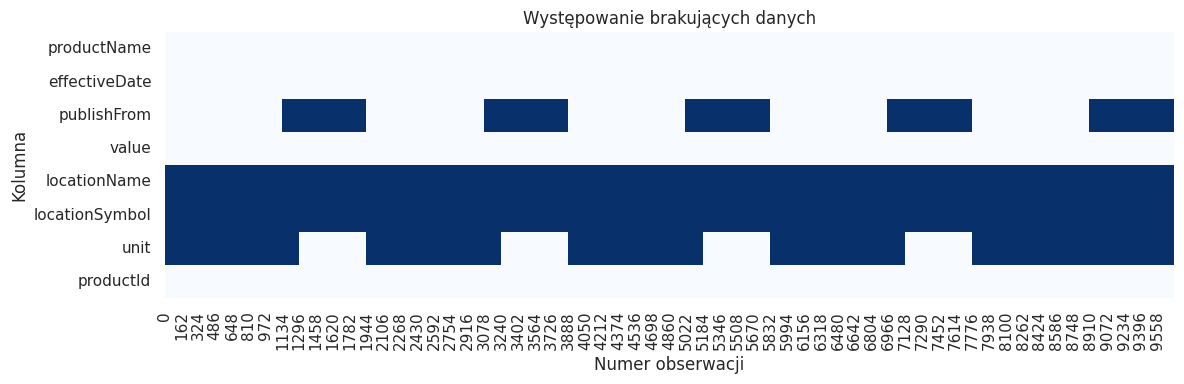

In [11]:
#wizualizacja braków

plt.figure(figsize=(12, 4))

sns.heatmap(
    df.isna().T,
    cmap="Blues",
    cbar=False,
    yticklabels=True
)

plt.title("Występowanie brakujących danych")
plt.xlabel("Numer obserwacji")
plt.ylabel("Kolumna")
plt.tight_layout()
plt.show()

Najwięcej brakujących wartości występuje w kolumnach locationName i locationSymbol, które są całkowicie puste. Znaczny odsetek braków występuje również w unit i publishFrom. Tutaj najważniejsze: kolumna value, zawierająca ceny, jest kompletna.

In [12]:
#kopia danych
df_clean_paliwa = df.copy()

In [13]:
#usuniecie pustych kolumn
df_clean_paliwa = df_clean_paliwa.drop(columns=["locationName", "locationSymbol"])

#konwersja dat (object)
df_clean_paliwa["effectiveDate"] = pd.to_datetime(df_clean_paliwa["effectiveDate"])
df_clean_paliwa["publishFrom"] = pd.to_datetime(df_clean_paliwa["publishFrom"])

#dodatkowe zmienne czasu dla ułatwienia
df_clean_paliwa["rok"] = df_clean_paliwa["effectiveDate"].dt.year
df_clean_paliwa["miesiac"] = df_clean_paliwa["effectiveDate"].dt.month

In [15]:
# Sprawdzenie jednostek
print(df_clean_paliwa["unit"].value_counts(dropna=False))

unit
NaN       7139
PLN/m3    2576
Name: count, dtype: int64


In [16]:
#uzupełnienie braków PLN/m3
df_clean_paliwa["unit"] = df_clean_paliwa["unit"].fillna("PLN/m3")

In [17]:
#przeliczenie ceny PLN/m3 na PLN/l
df_clean_paliwa["cena_za_litr"] = pd.to_numeric(df_clean_paliwa["value"], errors="coerce") / 1000

In [18]:
print(df_clean_paliwa["unit"].value_counts(dropna=False))

unit
PLN/m3    9715
Name: count, dtype: int64


In [19]:
display(df_clean_paliwa[["productName", "rok", "miesiac", "unit", "cena_za_litr"]].head())

,productName,rok,miesiac,unit,cena_za_litr
0,Pb95,2026,11,PLN/m3,5.307
1,Pb95,2026,11,PLN/m3,5.346
2,Pb95,2026,11,PLN/m3,5.296
3,Pb95,2026,11,PLN/m3,5.368
4,Pb95,2026,11,PLN/m3,5.438


In [20]:
#wybór paliw i lat 2019-2025
paliwa = ["Pb95", "Pb98", "ONEkodiesel"]
df_clean_paliwa = df_clean_paliwa[
    df_clean_paliwa["productName"].isin(paliwa) &
    df_clean_paliwa["rok"].between(2019, 2025)
].copy()

In [21]:
print("Liczba obserwacji po filtrowaniu:", len(df_clean_paliwa))
print(df_clean_paliwa["productName"].value_counts())
print("Zakres dat:", df_clean_paliwa["effectiveDate"].min(), "-", df_clean_paliwa["effectiveDate"].max())

Liczba obserwacji po filtrowaniu: 5181
productName
Pb95           1727
Pb98           1727
ONEkodiesel    1727
Name: count, dtype: int64
Zakres dat: 2019-01-01 00:00:00 - 2025-12-31 00:00:00


In [22]:
#pokaz danych
display(df_clean_paliwa[["productName", "value", "unit", "cena_za_litr"]].head(10))

,productName,value,unit,cena_za_litr
216,Pb95,4222.0,PLN/m3,4.222
217,Pb95,4228.0,PLN/m3,4.228
218,Pb95,4223.0,PLN/m3,4.223
219,Pb95,4220.0,PLN/m3,4.220
220,Pb95,4172.0,PLN/m3,4.172
221,Pb95,4178.0,PLN/m3,4.178
222,Pb95,4195.0,PLN/m3,4.195
223,Pb95,4221.0,PLN/m3,4.221
224,Pb95,4251.0,PLN/m3,4.251
225,Pb95,4276.0,PLN/m3,4.276


# Wszystkie notowania

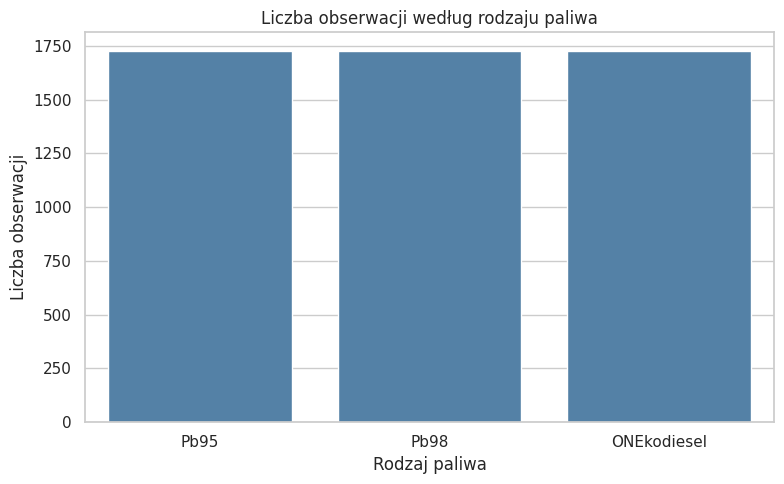

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean_paliwa,
    x="productName",
    color="steelblue"
)

plt.title("Liczba obserwacji według rodzaju paliwa")
plt.xlabel("Rodzaj paliwa")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()

W początkowym zbiorze danych znajdowało się 9715 obserwacji dotyczących pięciu rodzajów produktów paliwowych: Pb95, Pb98, ON Ekodiesel, ON Arctic 2 oraz ON Ekoterm. Ze względu na przyjęte pytanie badawcze, dotyczące wpływu zmian i niepewności cen paliw na ceny produktów codziennego użytku zdecydowano się skoncentrować analizę na trzech rodzajach paliw: Pb95, Pb98 oraz ON Ekodiesel.

Wybór ten wynika z ich znaczenia dla transportu samochodowego. Z głównej analizy wyłączono ON Arctic 2, będący specjalistycznym olejem napędowym przeznaczonym do niskich temperatur, oraz Ekoterm, wykorzystywany przede wszystkim do celów grzewczych.

Dodatkowo, w celu ujednolicenia ziarnistości czasowej z danymi dotyczącymi żywności, analizę ograniczono do lat 2019-2025, wykluczając obserwacje z 2026 roku.

Po zastosowaniu powyższych kryteriów w zbiorze pozostało 5181 obserwacji.

In [24]:
#statystyki opisowe dla pojedynczych notowan (PRZED agregacja)
display(df_clean_paliwa["cena_za_litr"].describe().round(3))

#statystyki kazdego paliwa
statystyki_paliwa = df_clean_paliwa.groupby("productName")["cena_za_litr"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
display(statystyki_paliwa.round(3))

,cena_za_litr
count,5181.000
mean,4.749
std,0.960
min,2.705
25%,4.046
50%,4.739
75%,5.203
max,8.311


,count,mean,median,std,min,max
productName,,,,,,
ONEkodiesel,1727,4.739,4.719,1.007,2.876,7.704
Pb95,1727,4.584,4.527,0.863,2.705,7.519
Pb98,1727,4.923,4.946,0.974,2.958,8.311


Po filtorwaniu posiadamy 5181 obserwacji, po 1727 dla każdego rodzaju paliwa.

Średnia cena paliw w analizowanym okresie wyniosła 4,749 PLN/l, natomiast mediana 4,739 PLN/l. Zbliżone wartości średniej i mediany wskazują na niewielką asymetrię ogólnego rozkładu cen. Odchylenie standardowe wyniosło 0,960 PLN/l, co świadczy o występowaniu zróżnicowania cen w badanym okresie. Najniższa odnotowana cena wyniosła 2,705 PLN/l, a najwyższa 8,311 PLN/l. Połowa obserwacji mieściła się w przedziale od 4,046 do 5,203 PLN/l, wyznaczonym przez pierwszy i trzeci kwartyl.

Analiza poszczególnych rodzajów paliw wykazała, że najwyższą średnią ceną charakteryzowała się benzyna Pb98 (4,923 PLN/l), następnie ON Ekodiesel (4,739 PLN/l), natomiast najniższą benzyna Pb95 (4,584 PLN/l). Podobną zależność zaobserwowano w przypadku median, które wyniosły odpowiednio 4,946 PLN/l dla Pb98, 4,719 PLN/l dla ON Ekodiesel oraz 4,527 PLN/l dla Pb95.

Największe zróżnicowanie cen wystąpiło w przypadku ON Ekodiesel, dla którego odchylenie standardowe wyniosło 1,007 PLN/l. Nieco mniejszą zmienność odnotowano dla Pb98 (0,974 PLN/l), natomiast najmniejszą dla Pb95 (0,863 PLN/l).

Najniższą pojedynczą cenę odnotowano dla Pb95 (2,705 PLN/l), a najwyższą dla Pb98 (8,311 PLN/l). W przypadku ON Ekodiesel ceny mieściły się w przedziale od 2,876 do 7,704 PLN/l.

In [26]:
#najniższa cena i data jej wystąpienia dla każdego paliwa
min_ceny_paliwa = df_clean_paliwa.loc[
    df_clean_paliwa.groupby("productName")["cena_za_litr"].idxmin(),
    ["productName", "effectiveDate", "cena_za_litr"]
]

display(min_ceny_paliwa)


#najwyższa cena i data jej wystąpienia dla każdego paliwa
max_ceny_paliwa = df_clean_paliwa.loc[
    df_clean_paliwa.groupby("productName")["cena_za_litr"].idxmax(),
    ["productName", "effectiveDate", "cena_za_litr"]
]

display(max_ceny_paliwa)


,productName,effectiveDate,cena_za_litr
5501,ONEkodiesel,2020-04-29,2.876
1615,Pb95,2020-04-29,2.705
3562,Pb98,2020-04-23,2.958


,productName,effectiveDate,cena_za_litr
5040,ONEkodiesel,2022-03-09,7.704
1097,Pb95,2022-06-02,7.519
3040,Pb98,2022-06-02,8.311


Histogram rozkładu cen paliw dla wszystkich notowań

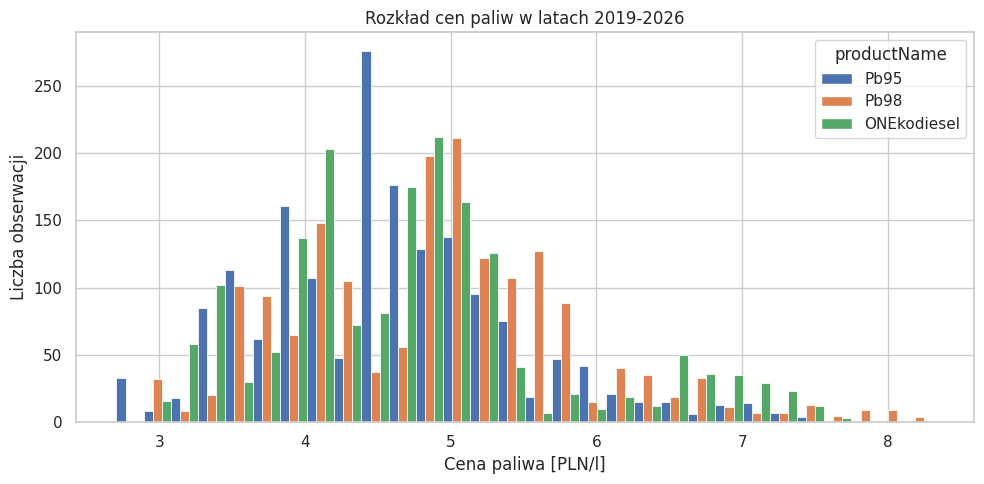

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean_paliwa,
    x="cena_za_litr",
    hue="productName",
    bins=30,
    multiple="dodge",
    alpha=1
)

plt.title("Rozkład cen paliw w latach 2019-2026")
plt.xlabel("Cena paliwa [PLN/l]")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()

Histogram przedstawia rozkład cen trzech rodzajów paliw: Pb95, Pb98 oraz ON Ekodiesel w latach 2019–2025, na podstawie 5181 pojedynczych notowań cen.

Największa koncentracja obserwacji występuje w przedziale około 4-5,5 PLN/l, przy czym rozkład cen Pb98 jest przesunięty w kierunku wyższych wartości w porównaniu z Pb95.

Ceny ON Ekodiesel charakteryzują się największym rozproszeniem, co jest zgodne z wcześniej obliczonym najwyższym odchyleniem standardowym (1,007 PLN/l). Dla wszystkich trzech paliw widoczne są również obserwacje w wyższych przedziałach cenowych, wskazujące na występowanie okresów podwyższonych cen.

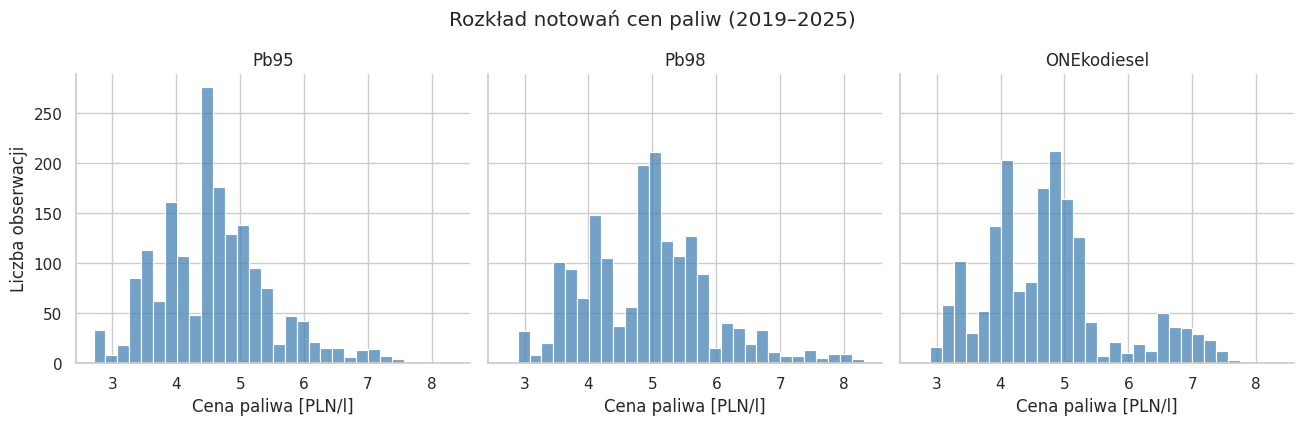

In [27]:
#histogram rozkladu wszystkich cen - kazde paliwo osobno
g = sns.displot(
    data=df_clean_paliwa,
    x="cena_za_litr",
    col="productName",
    col_order=paliwa,
    bins=30,
    height=4,
    aspect=1.1,
    color="steelblue"
)
g.set_axis_labels("Cena paliwa [PLN/l]", "Liczba obserwacji")
g.set_titles("{col_name}")
g.fig.suptitle("Rozkład notowań cen paliw (2019–2025)", y=1.06)
plt.show()

Boxplot - porównanie rozkładów cen

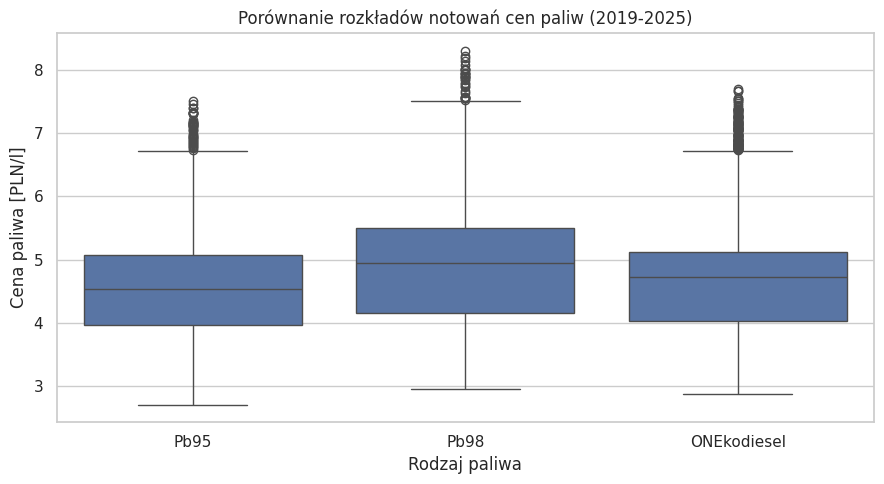

In [29]:
#boxplot - porownanie rozkladow wszystkich notowan
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean_paliwa, x="productName", y="cena_za_litr", order=paliwa)
plt.title("Porównanie rozkładów notowań cen paliw (2019-2025)")
plt.xlabel("Rodzaj paliwa")
plt.ylabel("Cena paliwa [PLN/l]")
plt.tight_layout()
plt.show()

Wykres pudełkowy przedstawia zróżnicowanie cen trzech rodzajów paliw w latach 2019–2025, na podstawie 5181 pojedynczych notowań cen. Najwyższą medianą charakteryzuje się benzyna Pb98 (4,946 PLN/l), natomiast najniższą Pb95 (4,527 PLN/l). Mediana cen ON Ekodiesel wynosi 4,719 PLN/l.

ON Ekodiesel wykazuje największe odchylenie standardowe cen spośród analizowanych paliw (1,007 PLN/l), co wskazuje na ich większe zróżnicowanie w badanym okresie. Najmniejszą zmienność odnotowano w przypadku benzyny Pb95 (0,863 PLN/l).

Dla wszystkich trzech rodzajów paliw widoczne są potencjalne wartości odstające po stronie wysokich cen, które mogą odpowiadać okresom znacznych podwyżek.

productName,ONEkodiesel,Pb95,Pb98
productName,,,
ONEkodiesel,1.00,0.96,0.96
Pb95,0.96,1.00,0.99
Pb98,0.96,0.99,1.00


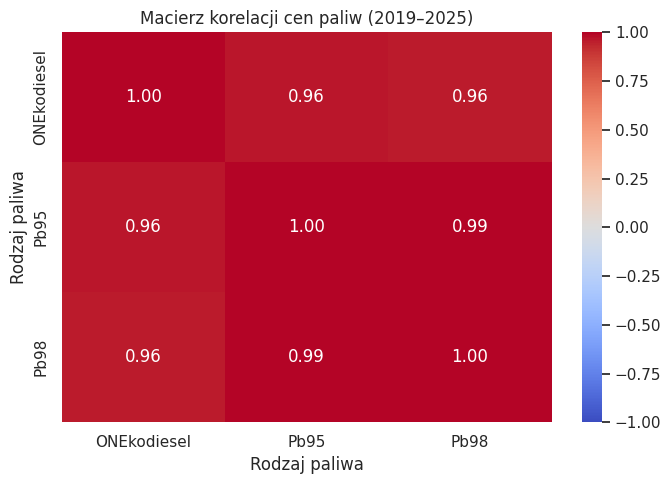

In [30]:
#przygotowanie tabeli cen paliw dla kazdej daty
ceny = df_clean_paliwa.pivot(
    index="effectiveDate",
    columns="productName",
    values="cena_za_litr"
)

#macierz korelacji wszystkich notowan
korelacje = ceny.corr()

display(korelacje.round(2))

plt.figure(figsize=(7, 5))

sns.heatmap(
    korelacje,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Macierz korelacji cen paliw (2019–2025)")
plt.xlabel("Rodzaj paliwa")
plt.ylabel("Rodzaj paliwa")
plt.tight_layout()
plt.show()

Macierz korelacji przedstawia zależności pomiędzy cenami trzech rodzajów paliw: Pb95, Pb98 oraz ON Ekodiesel w latach 2019-2025, na podstawie pojedynczych notowań cen przed agregacją do poziomu miesięcznego i rocznego.

Najsilniejszą dodatnią korelację zaobserwowano pomiędzy cenami benzyny Pb95 i Pb98 (r = 0,99), co wskazuje na niemal identyczny kierunek ich zmian. W przypadku ON Ekodiesel korelacja zarówno z Pb95, jak i Pb98 wyniosła 0,96, co również świadczy o bardzo silnej dodatniej zależności między cenami tych paliw.
Otrzymane wyniki wskazują, że ceny wszystkich trzech rodzajów paliw zmieniały się w podobnym kierunku w analizowanym okresie. Wzrostom cen jednego paliwa zazwyczaj towarzyszyły wzrosty cen pozostałych.

Wysokie współczynniki korelacji sugerują, że ceny analizowanych paliw mogą reagować na podobne czynniki rynkowe. Należy jednak zaznaczyć, że korelacja nie oznacza zależności przyczynowo-skutkowej.

# Agregacja: notowania → miesiąc → rok

In [32]:
#ETAP 1: mediana cen dla kazdego miesiaca i paliwa
ceny_miesieczne_paliwa = df_clean_paliwa.groupby(["rok", "miesiac", "productName"]
)["cena_za_litr"].median().reset_index()

print("Liczba median miesiecznych:", len(ceny_miesieczne_paliwa))
display(ceny_miesieczne_paliwa.head(12))

Liczba median miesiecznych: 252


,rok,miesiac,productName,cena_za_litr
0,2019,1,ONEkodiesel,3.8780
1,2019,1,Pb95,3.5125
2,2019,1,Pb98,3.7590
3,2019,2,ONEkodiesel,3.9975
4,2019,2,Pb95,3.6370
5,2019,2,Pb98,3.9090
6,2019,3,ONEkodiesel,4.0445
7,2019,3,Pb95,3.7730
8,2019,3,Pb98,4.0130
9,2019,4,ONEkodiesel,4.1440


Zastosowanie mediany zamiast średniej wynika z jej mniejszej wrażliwości na wartości skrajne, które mogą pojawiać się w okresach gwałtownych zmian cen paliw. Dzięki temu mediana pozwala lepiej przedstawić typowy poziom cen w danym miesiącu.

Agregacja miesięczna umożliwia również ograniczenie szczegółowości danych oraz zmniejszenie wpływu krótkookresowych wahań cen. W rezultacie z 5181 pojedynczych notowań otrzymano 252 mediany miesięczne (84 miesiące × 3 rodzaje paliwa).

Tak przygotowane dane stanowią podstawę do drugiego etapu agregacji, w którym zostaną obliczone mediany roczne. Pozwoli to uzyskać jednakową ziarnistość czasową danych paliwowych i danych dotyczących cen żywności, co umożliwi ich późniejsze porównanie.

In [33]:
#sprawdzenie liczby miesiecy dla kazdego roku i paliwa
liczba_miesiecy = ceny_miesieczne_paliwa.groupby(
    ["rok", "productName"]
).size().unstack()

display(liczba_miesiecy)

productName,ONEkodiesel,Pb95,Pb98
rok,,,
2019,12,12,12
2020,12,12,12
2021,12,12,12
2022,12,12,12
2023,12,12,12
2024,12,12,12
2025,12,12,12


In [34]:
#ETAP 2: mediana roczna obliczana z median miesiecznych
ceny_roczne_paliwa = ceny_miesieczne_paliwa.groupby(
    ["rok", "productName"]
)["cena_za_litr"].median().reset_index()

#lata w wierszach, paliwa w kolumnach
ceny_roczne_paliwa = ceny_roczne_paliwa.pivot(
    index="rok", columns="productName", values="cena_za_litr"
)

print("Liczba median rocznych:", ceny_roczne_paliwa.size)
display(ceny_roczne_paliwa.round(3))

Liczba median rocznych: 21


productName,ONEkodiesel,Pb95,Pb98
rok,,,
2019,4.026,3.912,4.116
2020,3.349,3.431,3.598
2021,4.228,4.361,4.600
2022,6.692,5.941,6.386
2023,5.127,5.121,5.494
2024,4.985,4.902,5.422
2025,4.664,4.507,4.950


W drugim etapie przeprowadzono agregację danych miesięcznych do poziomu rocznego. Dla każdego rodzaju paliwa obliczono medianę z 12 median miesięcznych przypadających na dany rok. Zastosowanie takiego podejścia pozwala ograniczyć wpływ krótkookresowych wahań cen oraz zapewnić jednakową wagę poszczególnym miesiącom, niezależnie od liczby notowań w danym miesiącu. Ponowne wykorzystanie mediany zmniejsza również wpływ skrajnych wartości miesięcznych.

W wyniku agregacji otrzymano 21 median rocznych (7 lat × 3 rodzaje paliwa), obejmujących okres 2019-2025. Najniższe roczne mediany cen wszystkich trzech paliw odnotowano w 2020 roku. Wyniosły one 3,349 PLN/l dla ON Ekodiesel, 3,431 PLN/l dla Pb95 oraz 3,598 PLN/l dla Pb98. Najwyższe wartości wystąpiły natomiast w 2022 roku, kiedy mediana cen ON Ekodiesel osiągnęła 6,692 PLN/l, Pb95 - 5,941 PLN/l, a Pb98 - 6,386 PLN/l.

Po 2022 roku zaobserwowano stopniowy spadek rocznych median cen wszystkich analizowanych paliw. W 2025 roku wyniosły one odpowiednio 4,664 PLN/l dla ON Ekodiesel, 4,507 PLN/l dla Pb95 oraz 4,950 PLN/l dla Pb98.

Przeprowadzona dwuetapowa agregacja pozwoliła sprowadzić dane paliwowe do rocznej ziarnistości czasowej, zgodnej z danymi dotyczącymi cen żywności. Dzięki temu możliwe będzie przeprowadzenie dalszej analizy porównawczej obu zbiorów danych.

In [35]:
#porownanie metody dwuetapowej z bezposrednia mediana roczna
mediany_bezposrednie = df_clean_paliwa.groupby(
    ["rok", "productName"]
)["cena_za_litr"].median().unstack()

print("Mediany roczne z median miesiecznych:")
display(ceny_roczne_paliwa.round(3))
print("Roznica wzgledem median bezposrednich (PLN/l):")
display((ceny_roczne_paliwa - mediany_bezposrednie).round(3))

Mediany roczne z median miesiecznych:


productName,ONEkodiesel,Pb95,Pb98
rok,,,
2019,4.026,3.912,4.116
2020,3.349,3.431,3.598
2021,4.228,4.361,4.600
2022,6.692,5.941,6.386
2023,5.127,5.121,5.494
2024,4.985,4.902,5.422
2025,4.664,4.507,4.950


Roznica wzgledem median bezposrednich (PLN/l):


productName,ONEkodiesel,Pb95,Pb98
rok,,,
2019,-0.012,-0.017,-0.015
2020,-0.004,-0.007,-0.002
2021,-0.007,-0.026,-0.045
2022,-0.019,-0.026,-0.015
2023,-0.002,-0.029,-0.027
2024,0.014,-0.017,0.053
2025,-0.027,0.001,-0.000


W celu sprawdzenia wpływu przyjętej metody agregacji porównano mediany roczne obliczone na dwa sposoby: bezpośrednio ze wszystkich notowań cen w danym roku oraz dwuetapowo, poprzez wyznaczenie median miesięcznych, a następnie mediany z tych wartości dla każdego roku.

Uzyskane wyniki wskazują, że różnice pomiędzy obiema metodami są niewielkie. W większości przypadków mediany roczne obliczone z median miesięcznych przyjmowały nieco niższe wartości niż mediany wyznaczone bezpośrednio ze wszystkich notowań. Największą różnicę zaobserwowano dla benzyny Pb98 w 2024 roku, kiedy mediana obliczona dwuetapowo była wyższa o 0,053 PLN/l. Z kolei w 2021 roku dla tego samego paliwa była niższa o 0,045 PLN/l.

Różnice wynikają ze sposobu uwzględniania obserwacji. W przypadku agregacji bezpośredniej każde notowanie ceny ma jednakowe znaczenie, natomiast w agregacji dwuetapowej każdy miesiąc jest reprezentowany przez jedną medianę, niezależnie od liczby notowań w tym miesiącu.

Do dalszej analizy przyjęto metodę dwuetapową, ponieważ umożliwia ona stopniowe ograniczenie szczegółowości danych z poziomu pojedynczych notowań do miesięcznego, a następnie rocznego. Zapewnia również jednakową wagę poszczególnym miesiącom oraz pozwala uzyskać roczną ziarnistość czasową zgodną z danymi dotyczącymi cen żywności.

Niewielkie różnice między wynikami obu metod wskazują, że zastosowany sposób agregacji nie zmienia zasadniczego obrazu zmian cen paliw w latach 2019-2025.

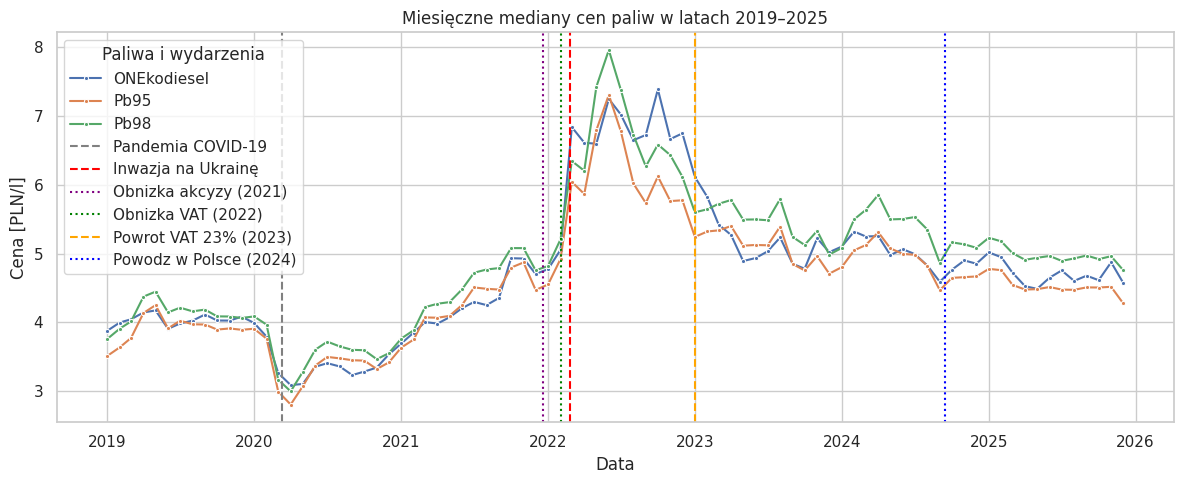

In [38]:
#wykres median miesiecznych w czasie
ceny_miesieczne_wykres = ceny_miesieczne_paliwa.copy()
ceny_miesieczne_wykres["data"] = pd.to_datetime(
    dict(year=ceny_miesieczne_wykres["rok"], month=ceny_miesieczne_wykres["miesiac"], day=1)
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=ceny_miesieczne_wykres, x="data", y="cena_za_litr", hue="productName", marker="o", markersize=3)
plt.axvline(pd.Timestamp("2020-03-11"), linestyle="--", color="gray", label="Pandemia COVID-19")
plt.axvline(pd.Timestamp("2022-02-24"), linestyle="--", color="red", label="Inwazja na Ukrainę")

#wydarzenia gospodarcze w Polsce

#obnizka akcyzy na paliwa
plt.axvline(
    pd.Timestamp("2021-12-20"),
    color="purple", linestyle=":",
    label="Obnizka akcyzy (2021)"
)

#obnizka VAT na paliwa
plt.axvline(
    pd.Timestamp("2022-02-01"),
    color="green", linestyle=":",
    label="Obnizka VAT (2022)"
)

#powrot VAT do 23%
plt.axvline(
    pd.Timestamp("2023-01-01"),
    color="orange", linestyle="--",
    label="Powrot VAT 23% (2023)"
)

#powodz w Polsce
plt.axvline(
    pd.Timestamp("2024-09-13"),
    color="blue", linestyle=":",
    label="Powodz w Polsce (2024)"
)

plt.title("Miesięczne mediany cen paliw w latach 2019-2025")
plt.xlabel("Data")
plt.ylabel("Cena [PLN/l]")
plt.legend(title="Paliwa i wydarzenia")
plt.tight_layout()
plt.show()

In [39]:
#procentowe zmiany median miesiecznych (miesiac do miesiaca)
ceny_miesieczne_tabela = ceny_miesieczne_wykres.pivot(
    index="data", columns="productName", values="cena_za_litr"
)
zmiany_miesieczne_paliwa = ceny_miesieczne_tabela.pct_change(fill_method=None) * 100

display(zmiany_miesieczne_paliwa.head(10).round(2))

#zmiennosc miesiecznych zmian - odchylenie standardowe
print("Odchylenie standardowe miesięcznych zmian [%]:")
display(zmiany_miesieczne_paliwa.std().round(2))

productName,ONEkodiesel,Pb95,Pb98
data,,,
2019-01-01,NaN,NaN,NaN
2019-02-01,3.08,3.54,3.99
2019-03-01,1.18,3.74,2.66
2019-04-01,2.46,9.62,9.00
2019-05-01,0.70,2.76,1.65
2019-06-01,-6.39,-7.96,-6.78
2019-07-01,1.97,2.89,1.66
2019-08-01,1.04,-1.30,-1.27
2019-09-01,2.21,-0.09,0.60


Odchylenie standardowe miesięcznych zmian [%]:


,0
productName,
ONEkodiesel,6.05
Pb95,5.91
Pb98,5.92


Przeprowadzono analizę procentowych zmian miesięcznych median cen trzech rodzajów paliw: Pb95, Pb98 oraz ON Ekodiesel w latach 2019–2025. Zmiany obliczono w stosunku do poprzedniego miesiąca, co pozwala określić kierunek oraz skalę krótkookresowych wahań cen. W przedstawionych wynikach dla 2019 roku widoczne są zarówno wzrosty, jak i spadki cen paliw. Przykładowo w kwietniu 2019 roku mediana ceny Pb95 wzrosła o 9,62%, a Pb98 o 9,00% względem poprzedniego miesiąca. Z kolei w czerwcu 2019 roku odnotowano spadki cen wszystkich trzech paliw, wynoszące od 6,39% do 7,96%.

W celu oceny zmienności miesięcznych zmian cen obliczono odchylenie standardowe procentowych zmian miesiąc do miesiąca. Najwyższą wartość uzyskano dla ON Ekodiesel (6,05 punktu procentowego), co wskazuje na największą zmienność jego miesięcznych zmian cen. Nieco niższe wartości odnotowano dla Pb98 (5,92 p.p.) oraz Pb95 (5,91 p.p.).

Różnice między analizowanymi paliwami są jednak niewielkie, co sugeruje, że skala miesięcznych wahań procentowych cen była zbliżona dla wszystkich trzech rodzajów paliw.

Analiza miesięcznych zmian cen pozwala lepiej uchwycić krótkookresową dynamikę rynku paliw, która może być mniej widoczna po agregacji danych do poziomu rocznego.

In [40]:
#statystyki opisowe dla 7 rocznych median kazdego paliwa
display(ceny_roczne_paliwa.describe().round(3))

#rok najnizszej i najwyzszej rocznej mediany
min_max_paliwa = pd.DataFrame({
    "Rok minimum": ceny_roczne_paliwa.idxmin(),
    "Cena minimalna": ceny_roczne_paliwa.min(),
    "Rok maksimum": ceny_roczne_paliwa.idxmax(),
    "Cena maksymalna": ceny_roczne_paliwa.max()
})
display(min_max_paliwa.round(3))

productName,ONEkodiesel,Pb95,Pb98
count,7.000,7.000,7.000
mean,4.724,4.596,4.938
std,1.059,0.823,0.933
min,3.349,3.431,3.598
25%,4.127,4.136,4.358
50%,4.664,4.507,4.950
75%,5.056,5.012,5.458
max,6.692,5.941,6.386


,Rok minimum,Cena minimalna,Rok maksimum,Cena maksymalna
productName,,,,
ONEkodiesel,2020,3.349,2022,6.692
Pb95,2020,3.431,2022,5.941
Pb98,2020,3.598,2022,6.386


Najwyższą średnią rocznych median cen odnotowano dla Pb98 (4,938 PLN/l), natomiast najniższą dla Pb95 (4,596 PLN/l). Największym zróżnicowaniem cen charakteryzował się ON Ekodiesel (odchylenie standardowe 1,059 PLN/l), a najmniejszym Pb95 (0,823 PLN/l).

Najniższe roczne mediany cen wszystkich paliw wystąpiły w 2020 roku, co można wiązać z pandemią COVID-19 i ograniczeniem zapotrzebowania na paliwa. Z kolei najwyższe wartości odnotowano w 2022 roku, na co mogła wpłynąć sytuacja na światowych rynkach energetycznych oraz inwazja Rosji na Ukrainę.

Wyniki wskazują na podobny przebieg zmian cen wszystkich analizowanych paliw, przy jednoczesnych różnicach w poziomie cen i ich zmienności.

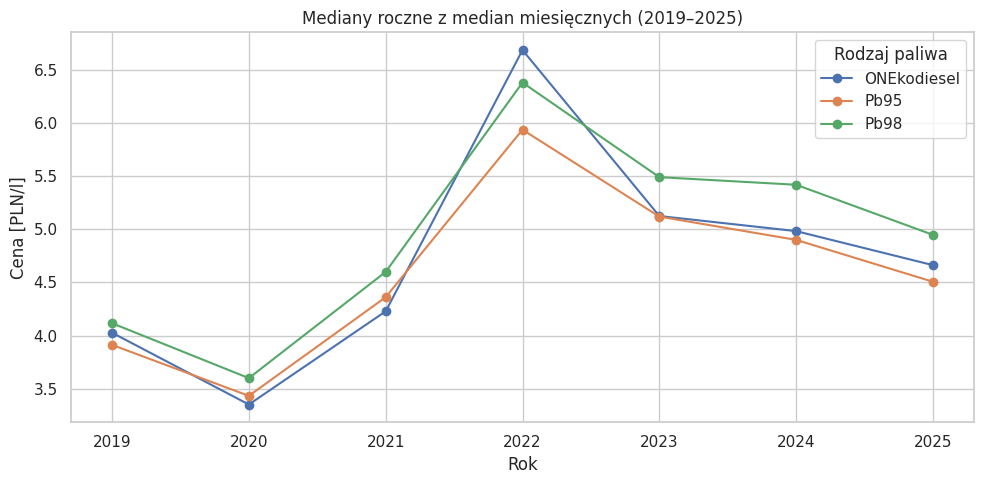

In [41]:
#wykres rocznych median cen paliw
ceny_roczne_paliwa.plot(marker="o", figsize=(10, 5))
plt.title("Mediany roczne z median miesięcznych (2019–2025)")
plt.xlabel("Rok")
plt.ylabel("Cena [PLN/l]")
plt.xticks(ceny_roczne_paliwa.index)
plt.legend(title="Rodzaj paliwa")
plt.tight_layout()
plt.show()

W 2020 roku zaobserwowano spadek cen wszystkich paliw, co można wiązać z pandemią COVID-19. Następnie ceny zaczęły rosnąć, osiągając najwyższe wartości w 2022 roku, szczególnie w przypadku ON Ekodiesel (6,692 PLN/l). Wzrost ten mógł być związany z sytuacją na światowych rynkach energetycznych oraz inwazją Rosji na Ukrainę.

Od 2023 roku widoczny jest stopniowy spadek cen wszystkich paliw. Pomimo tego w 2025 roku ich poziom pozostawał wyższy niż w 2019 roku.

Wszystkie trzy paliwa wykazują podobny kierunek zmian cen, jednak różnią się ich poziomem oraz skalą wahań.

productName,ONEkodiesel,Pb95,Pb98
rok,,,
2019,NaN,NaN,NaN
2020,-16.82,-12.29,-12.58
2021,26.25,27.13,27.85
2022,58.27,36.22,38.82
2023,-23.39,-13.80,-13.97
2024,-2.78,-4.29,-1.31
2025,-6.44,-8.06,-8.71


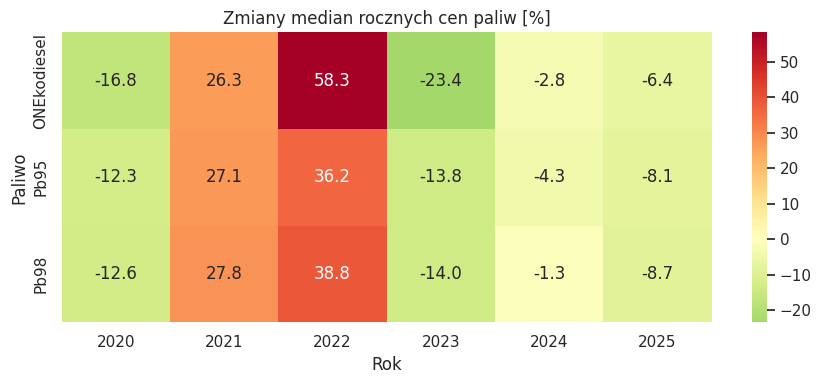

In [42]:
#procentowe zmiany rocznych median rok do roku
zmiany_roczne_paliwa = ceny_roczne_paliwa.pct_change(fill_method=None) * 100
display(zmiany_roczne_paliwa.round(2))

#heatmap zmian rocznych
plt.figure(figsize=(9, 4))
sns.heatmap(zmiany_roczne_paliwa.iloc[1:].T, annot=True, fmt=".1f", cmap="RdYlGn_r", center=0)
plt.title("Zmiany median rocznych cen paliw [%]")
plt.xlabel("Rok")
plt.ylabel("Paliwo")
plt.tight_layout()
plt.show()

W 2020 roku odnotowano spadek cen wszystkich trzech paliw, wynoszący od 12,29% dla Pb95 do 16,82% dla ON Ekodiesel. W 2021 roku nastąpiło odwrócenie trendu i wzrost cen o około 26–28%.

Największe wzrosty wystąpiły w 2022 roku, szczególnie w przypadku ON Ekodiesel, którego roczna mediana ceny wzrosła aż o 58,27%. Dla Pb95 i Pb98 wzrosty wyniosły odpowiednio 36,22% i 38,82%.

Od 2023 roku obserwowano spadki cen wszystkich analizowanych paliw. Największy spadek wystąpił w 2023 roku dla ON Ekodiesel (-23,39%). W latach 2024–2025 spadki były już mniejsze.

Wyniki wskazują na podobny kierunek rocznych zmian cen wszystkich paliw, przy czym ON Ekodiesel charakteryzował się największą skalą wahań, szczególnie w latach 2022–2023.

In [43]:
#procentowa zmiana median od 2019 do 2025 roku
zmiana_2019_2025_paliwa = (
    ceny_roczne_paliwa.loc[2025] / ceny_roczne_paliwa.loc[2019] - 1
) * 100

display(zmiana_2019_2025_paliwa.round(2))

,0
productName,
ONEkodiesel,15.83
Pb95,15.22
Pb98,20.26


W badanym okresie ceny wszystkich trzech rodzajów paliw wzrosły. Największy wzrost odnotowano dla benzyny Pb98 (20,26%), następnie dla ON Ekodiesel (15,83%), natomiast najmniejszy dla Pb95 (15,22%).

Wyniki wskazują, że pomimo spadków cen obserwowanych po 2022 roku, w 2025 roku roczne mediany cen wszystkich analizowanych paliw pozostawały wyższe niż w 2019 roku.

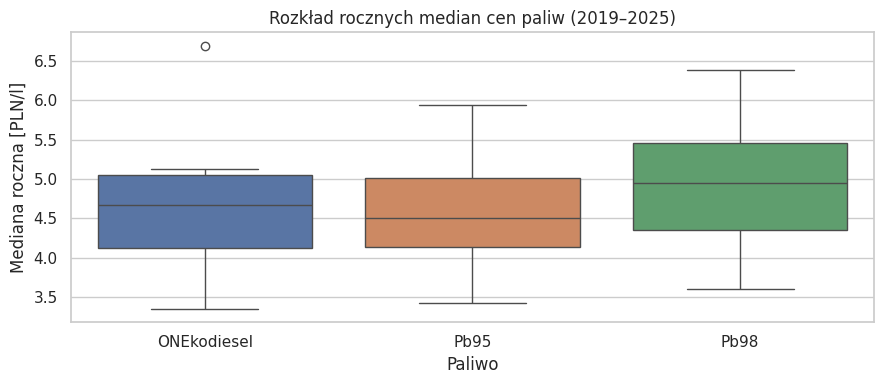

In [44]:
#boxplot SIEDMIU median rocznych dla kazdego paliwa
plt.figure(figsize=(9, 4))
sns.boxplot(data=ceny_roczne_paliwa)
plt.title("Rozkład rocznych median cen paliw (2019–2025)")
plt.xlabel("Paliwo")
plt.ylabel("Mediana roczna [PLN/l]")
plt.tight_layout()
plt.show()

Najwyższą medianą roczną charakteryzowała się benzyna Pb98 (4,950 PLN/l), natomiast najniższą Pb95 (4,507 PLN/l). Największe zróżnicowanie rocznych median cen występowało w przypadku ON Ekodiesel, co potwierdza najwyższe odchylenie standardowe (1,059 PLN/l).

Dla ON Ekodiesel widoczna jest również wartość odstająca odpowiadająca wysokiej medianie rocznej w 2022 roku (6,692 PLN/l).

Wyniki wskazują, że Pb98 charakteryzowała się najwyższym typowym poziomem cen, natomiast ON Ekodiesel największą zmiennością między analizowanymi latami.

productName,ONEkodiesel,Pb95,Pb98
productName,,,
ONEkodiesel,1.00,0.96,0.96
Pb95,0.96,1.00,1.00
Pb98,0.96,1.00,1.00


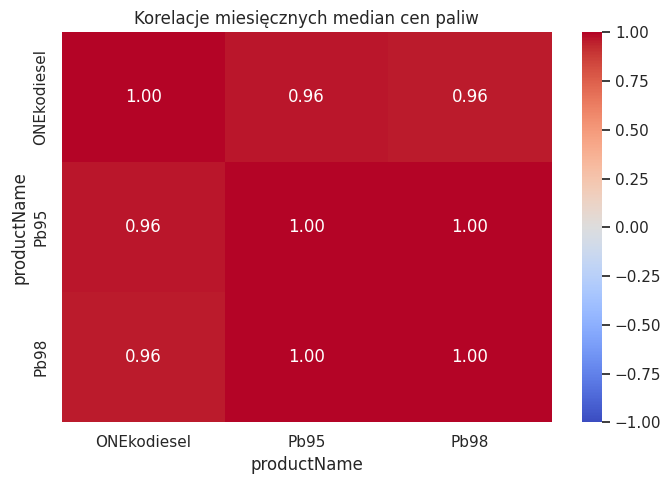

In [45]:
#korelacje median miesiecznych cen paliw
korelacje_miesieczne = ceny_miesieczne_tabela.corr()
display(korelacje_miesieczne.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(korelacje_miesieczne, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Korelacje miesięcznych median cen paliw")
plt.tight_layout()
plt.show()

productName,ONEkodiesel,Pb95,Pb98
productName,,,
ONEkodiesel,1.00,0.97,0.98
Pb95,0.97,1.00,1.00
Pb98,0.98,1.00,1.00


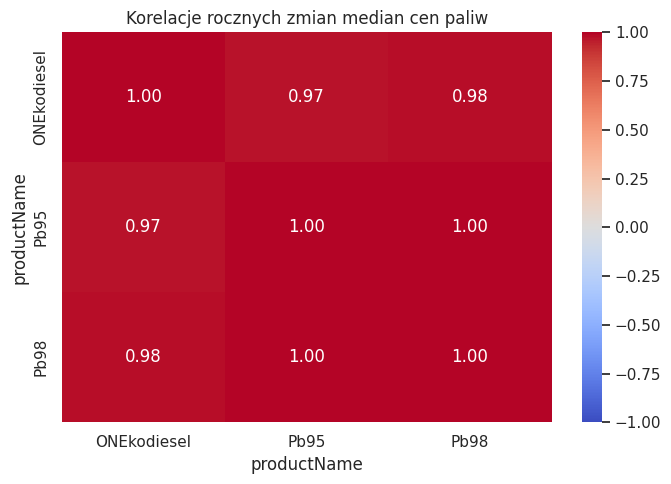

In [46]:
#korelacje rocznych ZMIAN procentowych (2019-2025)
korelacje_zmian_rocznych = zmiany_roczne_paliwa.corr()
display(korelacje_zmian_rocznych.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(korelacje_zmian_rocznych, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Korelacje rocznych zmian median cen paliw")
plt.tight_layout()
plt.show()

Wszystkie analizowane paliwa wykazują bardzo silną dodatnią korelację. Najwyższą zależność zaobserwowano pomiędzy Pb95 i Pb98 (r ≈ 1,00), co wskazuje na niemal identyczny kierunek i bardzo podobny przebieg ich rocznych zmian procentowych.

Korelacja ON Ekodiesel z Pb95 wyniosła 0,97, a z Pb98 0,98, co również świadczy o bardzo silnych dodatnich zależnościach.

Wyniki wskazują, że ceny wszystkich trzech paliw zmieniały się w podobnym kierunku, co może wynikać z oddziaływania wspólnych czynników rynkowych, takich jak zmiany cen ropy naftowej czy sytuacja gospodarcza.

productName,ONEkodiesel,Pb95,Pb98
rok,,,
2019,100.00,100.00,100.00
2020,83.18,87.71,87.42
2021,105.02,111.50,111.77
2022,166.22,151.89,155.15
2023,127.34,130.93,133.48
2024,123.80,125.32,131.73
2025,115.83,115.22,120.26


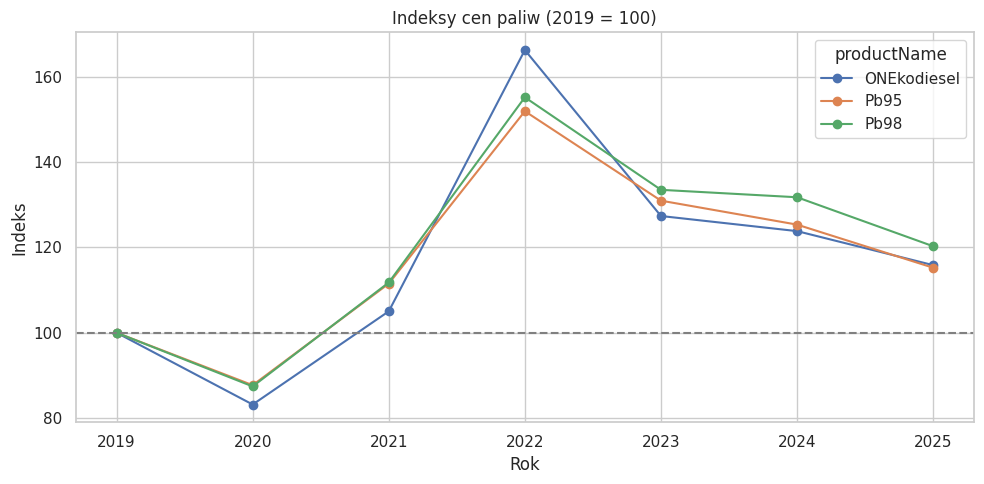

In [48]:
#indeksy cen na podstawie median rocznych
indeksy_paliwa = ceny_roczne_paliwa / ceny_roczne_paliwa.loc[2019] * 100

display(indeksy_paliwa.round(2))
indeksy_paliwa.plot(marker="o", figsize=(10, 5))
plt.axhline(100, color="gray", linestyle="--")
plt.title("Indeksy cen paliw (2019 = 100)")
plt.xlabel("Rok")
plt.ylabel("Indeks")
plt.xticks(indeksy_paliwa.index)
plt.tight_layout()
plt.show()

Wykres przedstawia indeksy rocznych median cen paliw w latach 2019–2025, przyjmując rok 2019 jako rok bazowy (2019 = 100).

W 2020 roku zaobserwowano spadek indeksów wszystkich paliw poniżej poziomu bazowego, natomiast od 2021 roku nastąpił ich wzrost.

Najwyższe wartości indeksów odnotowano w 2022 roku, szczególnie dla ON Ekodiesel (166,22), co oznacza wzrost ceny o 66,22% względem 2019 roku. Dla Pb95 i Pb98 indeksy wyniosły odpowiednio 151,89 i 155,15.

Od 2023 roku widoczny jest stopniowy spadek indeksów wszystkich trzech paliw. Pomimo tego w 2025 roku ceny nadal pozostawały powyżej poziomu z 2019 roku. Największy łączny wzrost odnotowano dla Pb98 (20,26%), następnie ON Ekodiesel (15,83%) oraz Pb95 (15,22%).

Wyniki wskazują na podobny przebieg zmian cen wszystkich analizowanych paliw, z największym wzrostem w 2022 roku i późniejszym stopniowym spadkiem.

In [49]:
#uklad taki jak w notatniku o jedzeniu: produkt w wierszu, lata w kolumnach
paliwa_jak_jedzenie = ceny_roczne_paliwa.T.copy()
paliwa_jak_jedzenie.columns = paliwa_jak_jedzenie.columns.astype(str)
paliwa_jak_jedzenie.index.name = "Produkt"

display(paliwa_jak_jedzenie.round(3))

rok,2019,2020,2021,2022,2023,2024,2025
Produkt,,,,,,,
ONEkodiesel,4.026,3.349,4.228,6.692,5.127,4.985,4.664
Pb95,3.912,3.431,4.361,5.941,5.121,4.902,4.507
Pb98,4.116,3.598,4.600,6.386,5.494,5.422,4.950


In [ ]:
#zapis danych z kolejnych etapow
ceny_miesieczne_paliwa.to_csv("paliwa_mediany_miesieczne.csv", index=False, sep=";", decimal=",")
ceny_roczne_paliwa.to_csv("paliwa_mediany_roczne.csv", sep=";", decimal=",")
paliwa_jak_jedzenie.to_csv("paliwa_jak_jedzenie.csv", sep=";", decimal=",")
df_clean_paliwa.to_csv("fuel_prices_clean.csv", index=False, sep=";", decimal=",")

print("Zapisano dane szczegolowe, mediany miesieczne i mediany roczne.")